In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

In [3]:
df = pd.read_csv("creditcard.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum().sum())

Dataset shape: (7973, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0     0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1     0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2     1 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3     1 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4     2 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

      

Class
0.0    7947
1.0      25
Name: count, dtype: int64
Class
0.0    99.686402
1.0     0.313598
Name: proportion, dtype: float64


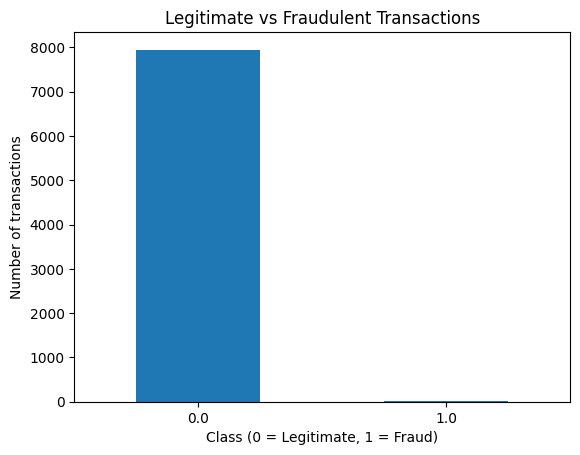

In [4]:
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True) * 100)

df["Class"].value_counts().plot(
    kind="bar",
    xlabel="Class (0 = Legitimate, 1 = Fraud)",
    ylabel="Number of transactions",
    title="Legitimate vs Fraudulent Transactions"
)

plt.xticks(rotation=0)
plt.show()

In [8]:
# Drop rows with missing values to prevent ValueError in train_test_split
df_cleaned = df.dropna()

X = df_cleaned.drop(columns=["Class"])
y = df_cleaned["Class"].astype(int)  # Cast to integer for classification labels

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training fraud cases:", y_train.sum())
print("Testing fraud cases:", y_test.sum())

Training records: 6377
Testing records: 1595
Training fraud cases: 20
Testing fraud cases: 5


In [9]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [10]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(
    y_test, y_pred, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_test, y_pred, zero_division=0
), 4))
print("F1 Score:", round(f1_score(
    y_test, y_pred, zero_division=0
), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

Accuracy: 0.9994
Precision: 0.8333
Recall: 1.0
F1 Score: 0.9091
ROC-AUC: 0.9999
PR-AUC: 0.9667

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1590
           1       0.83      1.00      0.91         5

    accuracy                           1.00      1595
   macro avg       0.92      1.00      0.95      1595
weighted avg       1.00      1.00      1.00      1595



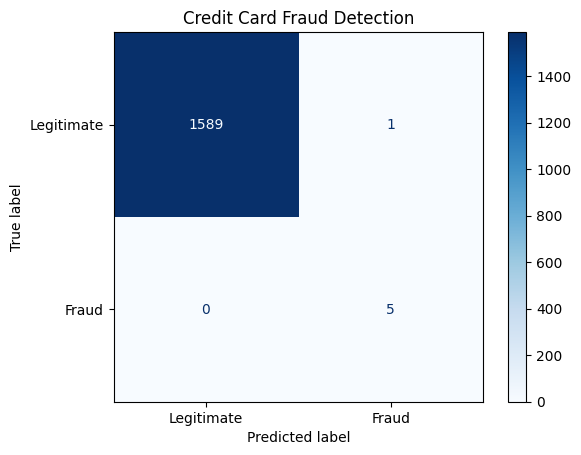

In [11]:
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
).plot(cmap="Blues", values_format="d")

plt.title("Credit Card Fraud Detection")
plt.show()

In [12]:
%pip install imbalanced-learn

In [13]:
from imblearn.under_sampling import RandomUnderSampler

sampler = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = sampler.fit_resample(
    X_train, y_train
)

print("Before undersampling:")
print(y_train.value_counts())

print("\nAfter undersampling:")
print(y_train_under.value_counts())

Before undersampling:
Class
0    6357
1      20
Name: count, dtype: int64

After undersampling:
Class
0    20
1    20
Name: count, dtype: int64


In [14]:
under_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

under_model.fit(X_train_under, y_train_under)

under_pred = under_model.predict(X_test)
under_prob = under_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, under_pred, zero_division=0
))

print("PR-AUC:", average_precision_score(
    y_test, under_prob
))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1590
           1       0.17      0.80      0.28         5

    accuracy                           0.99      1595
   macro avg       0.58      0.89      0.63      1595
weighted avg       1.00      0.99      0.99      1595

PR-AUC: 0.34


In [15]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, rf_pred, zero_division=0
))

print("PR-AUC:", average_precision_score(
    y_test, rf_prob
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1590
           1       1.00      0.80      0.89         5

    accuracy                           1.00      1595
   macro avg       1.00      0.90      0.94      1595
weighted avg       1.00      1.00      1.00      1595

PR-AUC: 1.0


In [16]:
models = {
    "Logistic Regression": (model, y_prob),
    "Undersampled Logistic Regression": (under_model, under_prob),
    "Random Forest": (rf_model, rf_prob)
}

results = []

for name, (trained_model, probabilities) in models.items():
    predictions = trained_model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

                           Model  Accuracy  Precision  Recall  F1 Score  PR-AUC
             Logistic Regression    0.9994     0.8333     1.0    0.9091  0.9667
Undersampled Logistic Regression    0.9868     0.1667     0.8    0.2759  0.3400
                   Random Forest    0.9994     1.0000     0.8    0.8889  1.0000


In [17]:
import joblib

joblib.dump(model, "fraud_detection_model.pkl")
print("Model saved successfully!")

Model saved successfully!
